In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math

In [3]:
image = cv2.imread('sar_3.jpg')
image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR) 
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

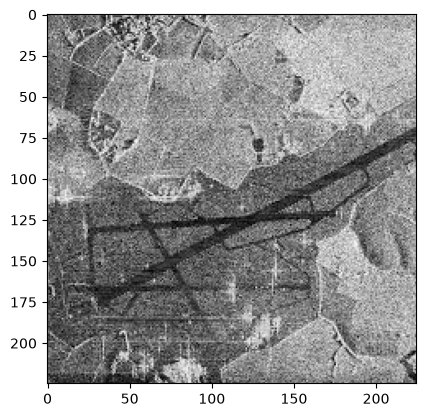

In [4]:
plt.imshow(image)

In [15]:
canny = cv2.Canny(image_gray, 200, 400, apertureSize = 3)
lines = cv2.HoughLines(canny, 1, np.pi / 180, 100)

if lines is not None:
        rhos = [l[0][0] for l in lines]
        thetas = [l[0][1] for l in lines]
        
        rho_avg = np.mean(rhos)
        theta_avg = np.mean(thetas)
        
        a = math.cos(theta_avg)
        b = math.sin(theta_avg)
        x0 = a * rho_avg
        y0 = b * rho_avg
        pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
        pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
        cv2.line(image, pt1, pt2, (255, 0, 0), 3, cv2.LINE_AA)

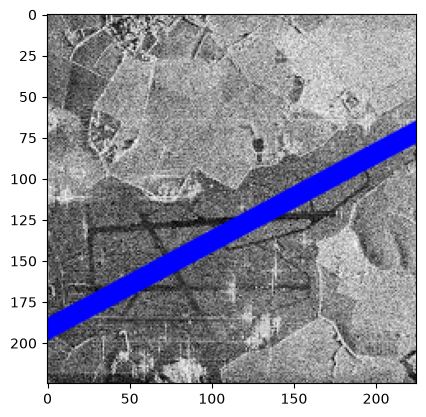

In [16]:
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

In [80]:
#ТОЧЕЧНАЯ

import copy

bin_img = copy.deepcopy(image_gray)
T  = 75
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255

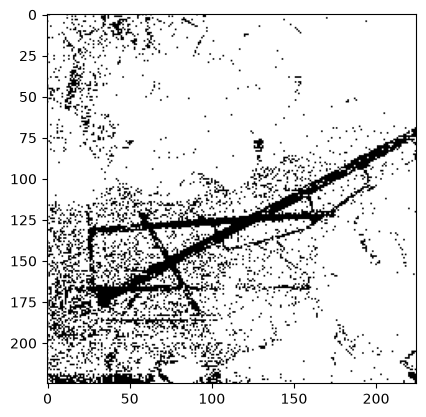

In [67]:
plt.imshow(bin_img, cmap="gray")

In [68]:
#ОТСУ
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

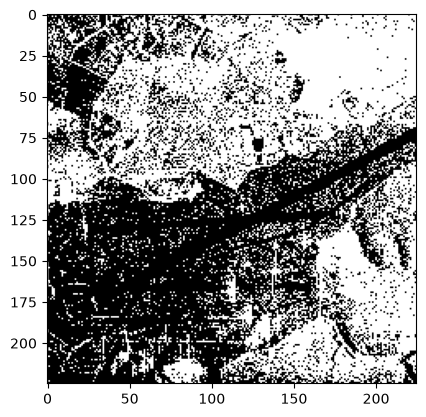

In [69]:
plt.imshow(th2, cmap="gray")

In [78]:
#АДАПТИВНАЯ
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,71,21)

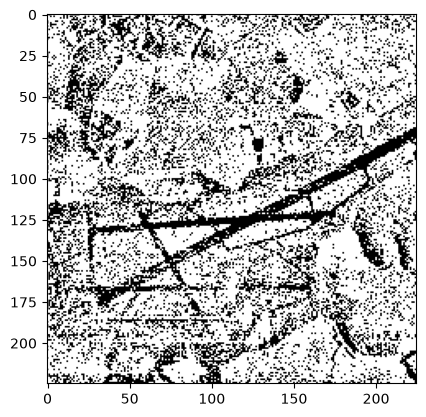

In [79]:
plt.imshow(th3, cmap="gray")